# Factoring through real modular arithmetic

This notebook builds a Fourier modular-add circuit and compute–swap–uncompute modular multipliers. It compares actual small circuits with an independent mathematical phase distribution. The pinned environment is Python 3.12/Qiskit 2.6.2; the public code package contains the original MIT implementation. Hardware execution and certified rotation synthesis are not performed.

In [1]:
from pathlib import Path
import sys
root = Path.cwd()
if not (root / "src").exists() and (root.parent / "src").exists():
    root = root.parent
if (root / "src").exists():
    sys.path.insert(0, str(root / "src"))
from openquantum.shor import (
    build_order_finding_circuit, decompose, simulate_phase_distribution,
    success_contract, reconstruct_order, factors_from_order,
    controlled_multiplier_gate, modular_adder_gate,
)
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector


## Circuit: N=15, a=2, t=4

All multiplier boxes have actual gate definitions. The code chooses constants with modular exponentiation and never looks up the order to construct the circuit. Four exponent bits are a favorable small-instance precision, distinct from generic t=2n. Work wires start at zero.

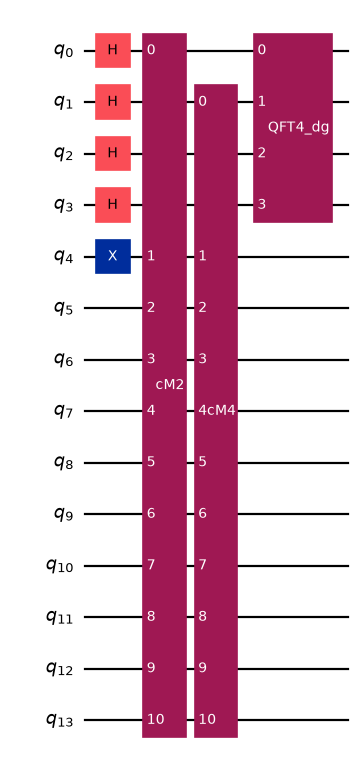

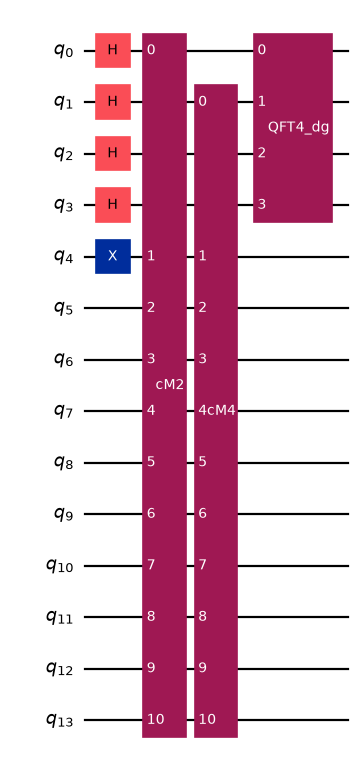

In [2]:
N, a, t = 15, 2, 4
circuit = build_order_finding_circuit(N, a, t)
circuit.draw(output="mpl", fold=36, scale=0.8)

In [3]:
result = simulate_phase_distribution(N, a, t)
assert result["max_probability_error"] < 1e-10
assert result["work_register_zero_probability"] > 1 - 1e-10
{key: result[key] for key in ("classical_reference_order", "max_probability_error", "work_register_zero_probability", "total_qubits")}

{'classical_reference_order': 4,
 'max_probability_error': 2.223221606811876e-14,
 'work_register_zero_probability': 0.9999999999999111,
 'total_qubits': 14}

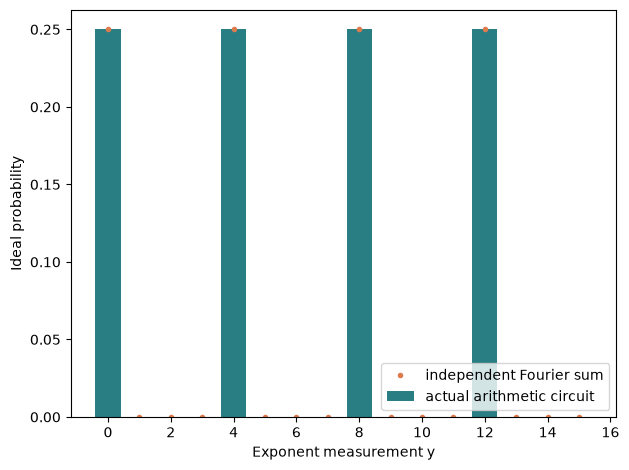

In [4]:
ys = np.arange(1 << t)
plt.bar(ys, result["probabilities"], label="actual arithmetic circuit", color="#287e83")
plt.plot(ys, result["reference_probabilities"], ".", label="independent Fourier sum", color="#dc7b4e")
plt.xlabel("Exponent measurement y")
plt.ylabel("Ideal probability")
plt.legend()
plt.tight_layout()
plt.show()

## Classical reconstruction and all repetitions

Convergent denominators are verified by modular exponentiation. A valid period can be a multiple of the minimal order at finite precision; gcd outputs are always checked. Neither classical order enumeration nor trial division is used in reconstruction. The separate enumerated order is an independent bounded validation reference.

In [5]:
contract = success_contract(N, a, t)
assert contract["ideal_factoring_success_probability_per_trial"] == 0.5
assert contract["serial_trials"] == 8
rng = np.random.default_rng(20261112)
p = np.array(result["probabilities"])
p /= p.sum()
outcomes = rng.choice(1 << t, size=contract["serial_trials"], p=p)
records = []
for y in outcomes:
    period = reconstruct_order(int(y), t, N, a)
    factors = factors_from_order(N, a, period)
    assert all(1 < factor < N and N % factor == 0 for factor in factors)
    records.append({"outcome": int(y), "verified_period": period, "factors": factors})
records

[{'outcome': 12, 'verified_period': 4, 'factors': [3, 5]},
 {'outcome': 0, 'verified_period': None, 'factors': []},
 {'outcome': 4, 'verified_period': 4, 'factors': [3, 5]},
 {'outcome': 12, 'verified_period': 4, 'factors': [3, 5]},
 {'outcome': 0, 'verified_period': None, 'factors': []},
 {'outcome': 4, 'verified_period': 4, 'factors': [3, 5]},
 {'outcome': 4, 'verified_period': 4, 'factors': [3, 5]},
 {'outcome': 8, 'verified_period': None, 'factors': []}]

## Less favorable nonexact phase: N=21, a=2, t=6

The order is six, which does not divide the Fourier grid size 64. Actual circuit probabilities are compared with the independent finite Fourier sum; the ideal verified-factor probability includes unsuccessful outcomes.

In [6]:
second = simulate_phase_distribution(21, 2, 6)
second_contract = success_contract(21, 2, 6)
assert second["max_probability_error"] < 1e-10
assert second_contract["serial_trials"] == 16
{"probability_error": second["max_probability_error"],
 "clean_work_probability": second["work_register_zero_probability"],
 "ideal_factor_success_per_trial": second_contract["ideal_factoring_success_probability_per_trial"],
 "trials_for_0.005_ideal_sampling_failure": second_contract["serial_trials"]}

{'probability_error': 6.997180612700049e-14,
 'clean_work_probability': 0.999999999999581,
 'ideal_factor_success_per_trial': 0.28798913703656037,
 'trials_for_0.005_ideal_sampling_failure': 16}

## Real arithmetic access and logical counts

A modulus-three arithmetic circuit is compact enough to expand visually. It uses QFT, controlled phases, X/CX and controlled swaps, not an opaque unitary matrix. Counts below include real multiplier construction and uncomputation.

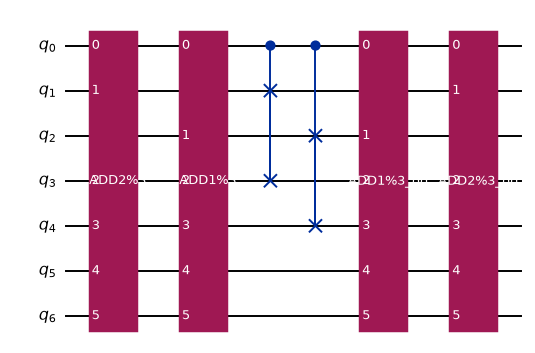

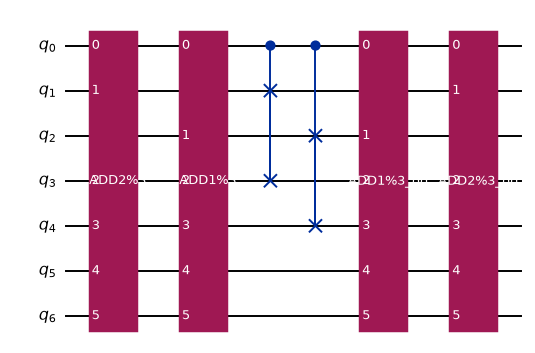

In [7]:
small = QuantumCircuit(7)
small.append(controlled_multiplier_gate(3, 2), range(7))
small.decompose(reps=1).draw(output="mpl", fold=32, scale=0.7)

In [8]:
compiled = decompose(build_order_finding_circuit(N, a, t, measure=True))
{"logical_qubits": compiled.num_qubits, "gate_counts": dict(compiled.count_ops()),
 "dependency_depth": compiled.depth(), "serial_trials": contract["serial_trials"],
 "full_workload_primitive_operations": int(sum(compiled.count_ops().values())) * contract["serial_trials"]}

{'logical_qubits': 14,
 'gate_counts': {'rz': 4356,
  'cx': 3778,
  'h': 442,
  'ry': 32,
  't': 32,
  'tdg': 24,
  'measure': 4,
  'x': 1},
 'dependency_depth': 4994,
 'serial_trials': 8,
 'full_workload_primitive_operations': 69352}

## Circuit generation without statevector simulation

Use `python scripts/generate_shor.py --modulus 33 --base 2 --phase-bits 12 --no-sim --no-scaling --output-dir artifacts/shor-33` from a source checkout. The circuit and resource guards are distinct from the 18-wire statevector cap. The default generator also emits a small scaling table, with larger circuits explicitly marked unvalidated by simulation. `--physical` runs the separate conditional QDK surface-code resource model, whose mean angle-synthesis fit is not an accuracy certificate.